## Código para checar se a área iluminada fixa funciona.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from structured_optics import *
from structured_optics.slmdisplay import My_SLM
from structured_optics.hologram import slm_hologram
import time 

from camera import *
from utils import *


In [22]:
def calc_fixwaist_lg(p, l):
    N = 2*p + abs(l) + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({p},{l}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu                  # waist on the SLM

def calc_fixwaist_hg(n):
    N = 2*n + 1
    A = C**2 / N                       # target w(z)^2
    disc = 1 - 16*z**2/(k**2 * A**2)
    if disc < 0:
        print(f"mode ({n},{0}) impossible: need A >= 4z/k")
        return None
    W2 = (A/2)*(1 + np.sqrt(disc))     # waist^2 at the SLM image plane
    W = np.sqrt(W2)
    return W/mu 

    

In [ ]:
#parametros laser e slm
pixel_size = 8e-6  #tamanho do pixel do slm 
lamb = 633e-9   #comprimento de onda
waist = 0.5e-3  #cintura do feixe que sai do slm
x_grating = 3
y_grating = 4

#parametros lentes e propagação
mu = 0.6930012799317185/0.5 #parâmetro de magnificação devido ao sistema 4F após o SLM
z = 0#0.60 #Distância entre o waist pós 4F e a amostra, utilizado para calcular fix std
C = 0.65e-3  #std a ser fixado


#parametros camera
EXPO = 1/9091   #exposição camera em segundos
BIT = 8     #bitdepth da camera
pixel_cam = 3.75e-6 #tamanho do pixel da camera
width_cam = 1280 #largura da camera
height_cam = 960 #altura da camera
NUM_BACK = 5 #numero de imagens para calcular o background


In [24]:
slm = My_SLM(1)
cam = init_camera(bitdepth=BIT, exposure_s = EXPO)

In [25]:

hg_modes = [[0,0], [0,1], [1,0], [2,0], [1,1], [0,2], [3,0], 
            [2,1], [1,2], [0,3], [4,0], [3,1], [2,2], [1,3], 
            [0,4], [5,0], [4,1], [3,2], [2,3], [1,4], [0,5]]
lg_modes = [[0,0], [0,1], [0,-1], [0,2], [1,0], [0,-2], [0,3], 
            [1,1], [1,-1], [0,-3], [0,4], [1, 2], [1,-2], [2, 0], 
            [0,-4], [0,5], [1,3], [1, -3], [2, 1], [2,-1], [0,-5]]


In [26]:
width = slm.width
height = slm.height


beam = Beam(nix = pixel_size*width/2, Dx = width,
            niy = pixel_size*height/2, Dy = height,
            waist = waist, lamb = lamb)

## Check Laguerre

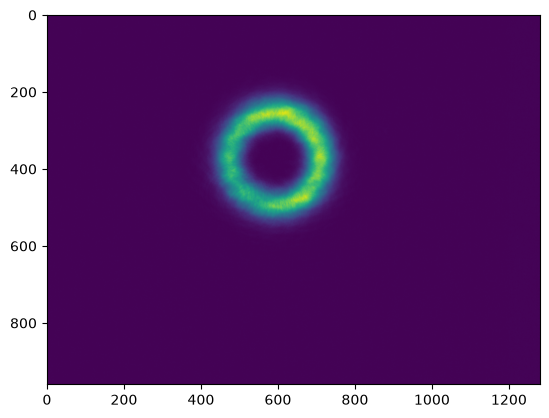

In [27]:
std_lg = []
k = beam.k()
for p, l in lg_modes:
    waist = calc_fixwaist_lg(p,l)
    if waist == None:
        continue
    else:
        beam.waist = waist
    beam.lg(l=l, p=p)
    holo = slm_hologram(beam, 3,4)
    slm.update_image(holo)
    time.sleep(0.2)
    img = take_picture(cam)
    if np.max(img) > 254:
        print("saturated")
    

    std = beam_std(img)['sigma_x']
    std_lg.append(std)

plt.figure()
plt.imshow(img)

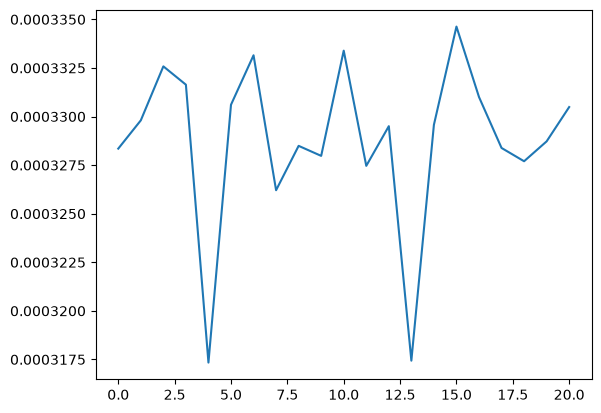

In [28]:
plt.plot(np.array(std_lg)*pixel_cam)
#plt.ylim(0,1e-3)

## Check Hermite

In [29]:
std_hg = []

for n in range(6):
    waist = calc_fixwaist_hg(n)
    if waist == None:
        continue
    else:
        beam.waist = waist
    beam.hg(n=n, m=0)
    holo = slm_hologram(beam, 3,4)
    slm.update_image(holo)
    time.sleep(0.2)
    img = take_picture(cam)

    std = beam_std(img)['sigma_x']
    std_hg.append(std)


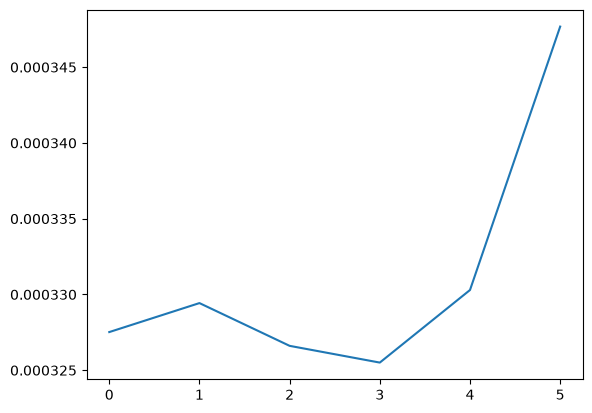

In [30]:
plt.plot(np.array(std_hg)*pixel_cam)
#plt.ylim(0, 1e-3)

In [31]:
slm.close()
close_camera(cam)